
# Exploratory Data Analysis (EDA) — HIGGS Dataset

**Project:** Machine Learning-Based Higgs Boson Signal Detection from Particle Collision Data

**Dataset:** HIGGS Dataset (UCI Machine Learning Repository)

**Dataset Size:** 11 Million Records

**Number of Features:** 28

**Target Variable:** Binary Classification (Higgs Signal Event = 1, Background Event = 0)

## 1. Introduction

This notebook performs Exploratory Data Analysis (EDA) on the complete HIGGS dataset to understand its structure, statistical properties, feature distributions, and data quality before preprocessing and machine learning model development.

### Objectives
- Load and inspect the complete dataset.
- Identify missing values and duplicate records.
- Analyze the target class distribution.
- Explore feature distributions and statistical properties.
- Identify potential outliers and correlations.
- Prepare insights for the preprocessing stage.



## 2. Dataset Access and Environment Setup

### 2.1 Mount Google Drive

The HIGGS dataset is stored in Google Drive. Google Drive is mounted to the Colab environment to provide access to the complete dataset without uploading it during every session.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [13]:

import os

dataset_folder = "/content/drive/MyDrive/Higgs-boson-signal-detection-ML/data/raw"

if os.path.exists(dataset_folder):
    print("Dataset folder found!")

    files = os.listdir(dataset_folder)

    print("\nAvailable files:")
    for file in files:
        print("-", file)
else:
    print("Dataset folder not found!")


Dataset folder found!

Available files:
- HIGGS.csv.gz



### 2.2 Check Google Colab Runtime Resources

Before loading the complete HIGGS dataset, the available system memory is examined to ensure that sufficient resources are available.

The dataset contains approximately 11 million observations and 29 columns, including 28 input features and one binary target variable.

The dataset will be loaded using the `float32` data type to reduce memory consumption while maintaining sufficient numerical precision for the machine learning analysis.


In [14]:

import psutil

memory = psutil.virtual_memory()

print("Total RAM: {:.2f} GB".format(
    memory.total / (1024**3)
))

print("Available RAM: {:.2f} GB".format(
    memory.available / (1024**3)
))

print("RAM Usage: {}%".format(
    memory.percent
))


Total RAM: 12.67 GB
Available RAM: 11.46 GB
RAM Usage: 9.5%


### 2.3 Load the Dataset

Load the complete HIGGS dataset using Pandas with float32 to reduce memory usage.

In [16]:

import pandas as pd
import numpy as np
import os
import time

dataset_folder = "/content/drive/MyDrive/Higgs-boson-signal-detection-ML/data/raw"

dataset_files = [
    f for f in os.listdir(dataset_folder)
    if f.lower().endswith((".csv", ".csv.gz"))
]

print("Available datasets:", dataset_files)

if len(dataset_files) != 1:
    raise ValueError("Expected exactly one CSV dataset.")

dataset_path = os.path.join(
    dataset_folder,
    dataset_files[0]
)

start_time = time.time()

df = pd.read_csv(
    dataset_path,
    header=None,
    dtype=np.float32
)

elapsed_time = time.time() - start_time

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(f"Loading time: {elapsed_time:.2f} seconds")
print(
    f"Memory usage: {df.memory_usage(deep=True).sum() / (1024**3):.2f} GB"
)


Available datasets: ['HIGGS.csv.gz']
Dataset loaded successfully!
Dataset shape: (11000000, 29)
Loading time: 98.51 seconds
Memory usage: 1.19 GB


In [17]:

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

assert df.shape == (11_000_000, 29), (
    f"Unexpected dataset shape: {df.shape}"
)


Rows: 11000000
Columns: 29

First 5 rows:


,0,1,2,3,4,5,6,7,8,9,...,19,20,21,22,23,24,25,26,27,28
0,1.0,0.869293,-0.635082,0.225690,0.327470,-0.689993,0.754202,-0.248573,-1.092064,0.000000,...,-0.010455,-0.045767,3.101961,1.353760,0.979563,0.978076,0.920005,0.721657,0.988751,0.876678
1,1.0,0.907542,0.329147,0.359412,1.497970,-0.313010,1.095531,-0.557525,-1.588230,2.173076,...,-1.138930,-0.000819,0.000000,0.302220,0.833048,0.985700,0.978098,0.779732,0.992356,0.798343
2,1.0,0.798835,1.470639,-1.635975,0.453773,0.425629,1.104875,1.282322,1.381664,0.000000,...,1.128848,0.900461,0.000000,0.909753,1.108330,0.985692,0.951331,0.803252,0.865924,0.780118
3,0.0,1.344385,-0.876626,0.935913,1.992050,0.882454,1.786066,-1.646778,-0.942383,0.000000,...,-0.678379,-1.360356,0.000000,0.946652,1.028704,0.998656,0.728281,0.869200,1.026736,0.957904
4,1.0,1.105009,0.321356,1.522401,0.882808,-1.205349,0.681466,-1.070464,-0.921871,0.000000,...,-0.373566,0.113041,0.000000,0.755856,1.361057,0.986610,0.838085,1.133295,0.872245,0.808487



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11000000 entries, 0 to 10999999
Data columns (total 29 columns):
 #   Column  Dtype  
---  ------  -----  
 0   0       float32
 1   1       float32
 2   2       float32
 3   3       float32
 4   4       float32
 5   5       float32
 6   6       float32
 7   7       float32
 8   8       float32
 9   9       float32
 10  10      float32
 11  11      float32
 12  12      float32
 13  13      float32
 14  14      float32
 15  15      float32
 16  16      float32
 17  17      float32
 18  18      float32
 19  19      float32
 20  20      float32
 21  21      float32
 22  22      float32
 23  23      float32
 24  24      float32
 25  25      float32
 26  26      float32
 27  27      float32
 28  28      float32
dtypes: float32(29)
memory usage: 1.2 GB



## 3. Dataset Structure

### 3.1 Rename Columns

Assign meaningful names to the target variable and 28 input features.


In [18]:

column_names = [
    "target",
    "lepton_pT",
    "lepton_eta",
    "lepton_phi",
    "missing_energy_magnitude",
    "missing_energy_phi",
    "jet1_pT",
    "jet1_eta",
    "jet1_phi",
    "jet1_b_tag",
    "jet2_pT",
    "jet2_eta",
    "jet2_phi",
    "jet2_b_tag",
    "jet3_pT",
    "jet3_eta",
    "jet3_phi",
    "jet3_b_tag",
    "jet4_pT",
    "jet4_eta",
    "jet4_phi",
    "jet4_b_tag",
    "m_jj",
    "m_jjj",
    "m_lv",
    "m_jlv",
    "m_bb",
    "m_wbb",
    "m_wwbb"
]

df.columns = column_names

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (11000000, 29)


,target,lepton_pT,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet1_pT,jet1_eta,jet1_phi,jet1_b_tag,...,jet4_eta,jet4_phi,jet4_b_tag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
0,1.0,0.869293,-0.635082,0.225690,0.327470,-0.689993,0.754202,-0.248573,-1.092064,0.000000,...,-0.010455,-0.045767,3.101961,1.353760,0.979563,0.978076,0.920005,0.721657,0.988751,0.876678
1,1.0,0.907542,0.329147,0.359412,1.497970,-0.313010,1.095531,-0.557525,-1.588230,2.173076,...,-1.138930,-0.000819,0.000000,0.302220,0.833048,0.985700,0.978098,0.779732,0.992356,0.798343
2,1.0,0.798835,1.470639,-1.635975,0.453773,0.425629,1.104875,1.282322,1.381664,0.000000,...,1.128848,0.900461,0.000000,0.909753,1.108330,0.985692,0.951331,0.803252,0.865924,0.780118
3,0.0,1.344385,-0.876626,0.935913,1.992050,0.882454,1.786066,-1.646778,-0.942383,0.000000,...,-0.678379,-1.360356,0.000000,0.946652,1.028704,0.998656,0.728281,0.869200,1.026736,0.957904
4,1.0,1.105009,0.321356,1.522401,0.882808,-1.205349,0.681466,-1.070464,-0.921871,0.000000,...,-0.373566,0.113041,0.000000,0.755856,1.361057,0.986610,0.838085,1.133295,0.872245,0.808487



### 3.2 Verify Features

Verify the feature names and data types.


In [19]:

print("Total columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nTarget values:")
print(df["target"].value_counts())


Total columns: 29

Column names:
['target', 'lepton_pT', 'lepton_eta', 'lepton_phi', 'missing_energy_magnitude', 'missing_energy_phi', 'jet1_pT', 'jet1_eta', 'jet1_phi', 'jet1_b_tag', 'jet2_pT', 'jet2_eta', 'jet2_phi', 'jet2_b_tag', 'jet3_pT', 'jet3_eta', 'jet3_phi', 'jet3_b_tag', 'jet4_pT', 'jet4_eta', 'jet4_phi', 'jet4_b_tag', 'm_jj', 'm_jjj', 'm_lv', 'm_jlv', 'm_bb', 'm_wbb', 'm_wwbb']

Data types:
float32    29
Name: count, dtype: int64

Target values:
target
1.0    5829123
0.0    5170877
Name: count, dtype: int64



## 4. Data Quality Analysis

### 4.1 Missing Values

Check for missing values in the dataset.


In [20]:

missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())


Missing values per column:
target                      0
lepton_pT                   0
lepton_eta                  0
lepton_phi                  0
missing_energy_magnitude    0
missing_energy_phi          0
jet1_pT                     0
jet1_eta                    0
jet1_phi                    0
jet1_b_tag                  0
jet2_pT                     0
jet2_eta                    0
jet2_phi                    0
jet2_b_tag                  0
jet3_pT                     0
jet3_eta                    0
jet3_phi                    0
jet3_b_tag                  0
jet4_pT                     0
jet4_eta                    0
jet4_phi                    0
jet4_b_tag                  0
m_jj                        0
m_jjj                       0
m_lv                        0
m_jlv                       0
m_bb                        0
m_wbb                       0
m_wwbb                      0
dtype: int64

Total missing values: 0



### 4.2 Infinite Values

Check for positive and negative infinite values.


In [21]:

import numpy as np

infinite_values = np.isinf(df.to_numpy()).sum()

print("Total infinite values:", infinite_values)


Total infinite values: 0



### 4.3 Target Validation

Verify that the target contains only binary class labels (0 and 1).


In [22]:

print("Unique target values:")
print(df["target"].unique())

invalid_targets = (~df["target"].isin([0, 1])).sum()

print("Invalid target values:", invalid_targets)


Unique target values:
[1. 0.]
Invalid target values: 0



### 4.4 Data Quality Summary

- **Missing Values:** 0
- **Infinite Values:** 0
- **Invalid Target Values:** 0
- **Target Classes:** 0 (Background), 1 (Signal)

**Conclusion:** The dataset passed the initial data quality checks and is suitable for further analysis.



## 5. Duplicate Records Analysis

### 5.1 Check Exact Duplicates

Identify records with identical feature values and target labels.


In [23]:

duplicate_count = df.duplicated().sum()

print("Total records:", len(df))
print("Duplicate records:", duplicate_count)
print(f"Duplicate percentage: {duplicate_count / len(df) * 100:.4f}%")


Total records: 11000000
Duplicate records: 278698
Duplicate percentage: 2.5336%



### 5.2 Check Conflicting Targets

Identify identical feature combinations associated with different target labels.


In [25]:

feature_columns = df.columns.drop("target")

conflicting_groups = (
    df.groupby(list(feature_columns), sort=False)["target"]
    .nunique()
)

conflicting_count = (conflicting_groups > 1).sum()

print("Feature groups with conflicting targets:", conflicting_count)


Feature groups with conflicting targets: 0



### 5.3 Duplicate Analysis Summary

- **Total Records:** 11,000,000
- **Exact Duplicate Records:** 278698
- **Conflicting Target Groups:** 0

**Conclusion:** Duplicate records and target consistency were examined to determine whether duplicate handling is required during preprocessing.



## 6. Target Class Distribution

### 6.1 Class Distribution

Analyze the distribution of signal and background events.


In [26]:

class_counts = df["target"].value_counts().sort_index()
class_percentages = df["target"].value_counts(
    normalize=True
).sort_index() * 100

print("Class Distribution:")
print(class_counts)

print("\nClass Percentages:")
print(class_percentages.round(2))


Class Distribution:
target
0.0    5170877
1.0    5829123
Name: count, dtype: int64

Class Percentages:
target
0.0    47.01
1.0    52.99
Name: proportion, dtype: float64



### 6.2 Class Distribution Visualization

Visualize the number of background and signal events.


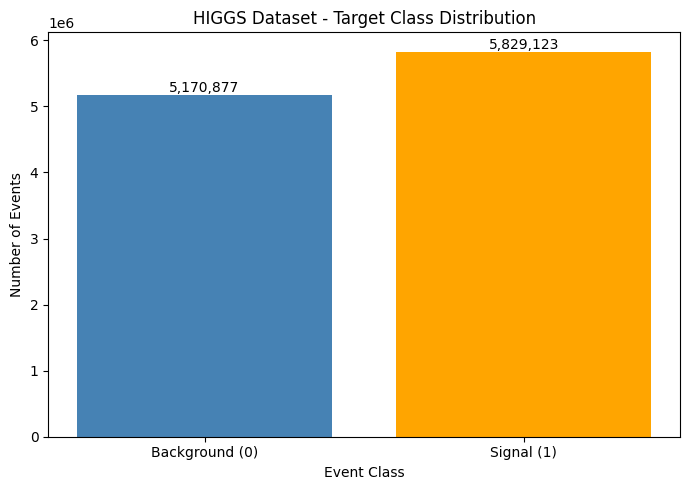

In [28]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Background (0)", "Signal (1)"],
    class_counts.values,
    color=["steelblue", "orange"]
)

plt.title("HIGGS Dataset - Target Class Distribution")
plt.xlabel("Event Class")
plt.ylabel("Number of Events")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()



### 6.3 Class Distribution Pie Chart

Visualize the percentage of signal and background events.


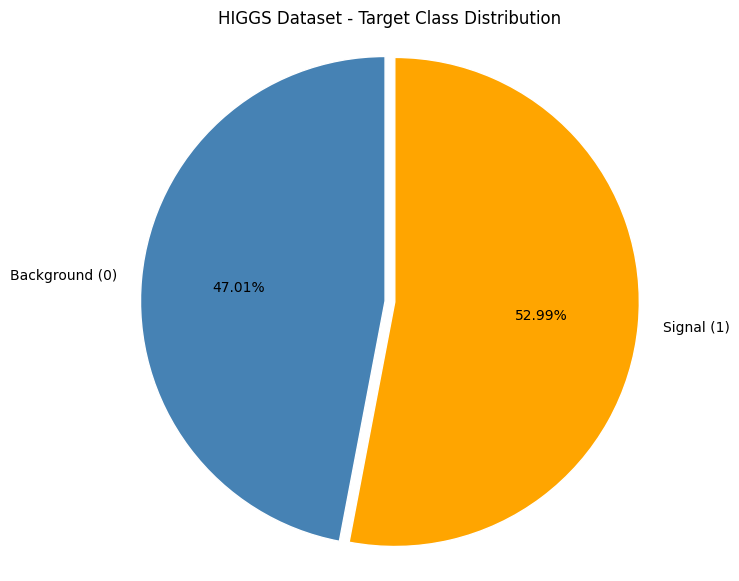

In [29]:

plt.figure(figsize=(7, 7))

plt.pie(
    class_counts.values,
    labels=["Background (0)", "Signal (1)"],
    autopct="%1.2f%%",
    startangle=90,
    colors=["steelblue", "orange"],
    explode=(0.02, 0.02),
    wedgeprops={"edgecolor": "white"}
)

plt.title("HIGGS Dataset - Target Class Distribution")
plt.axis("equal")
plt.show()



### 6.4 Class Distribution Summary

- **Background (0):** 47.01%
- **Signal (1):** 52.99%

**Conclusion:** The class distribution was analyzed to identify potential class imbalance. Stratified splitting will be used during preprocessing to preserve the class proportions.



## 7. Descriptive Statistical Analysis

### 7.1 Summary Statistics

Analyze the statistical properties of the numerical features.


In [30]:

feature_df = df.drop(columns=["target"])

statistics = feature_df.describe().T

display(statistics)


,count,mean,std,min,25%,50%,75%,max
lepton_pT,11000000.0,0.991466,0.560722,0.274697,0.590753,0.853371,1.236226,12.098914
lepton_eta,11000000.0,-0.000008,1.000114,-2.434976,-0.738322,-0.000054,0.738214,2.434868
lepton_phi,11000000.0,-0.000013,1.000483,-1.742508,-0.871931,-0.000241,0.870994,1.743236
missing_energy_magnitude,11000000.0,0.998536,0.594943,0.000237,0.576816,0.891628,1.293056,15.396821
missing_energy_phi,11000000.0,0.000026,1.000413,-1.743944,-0.871208,0.000213,0.871471,1.743257
jet1_pT,11000000.0,0.990915,0.470170,0.137502,0.678993,0.894819,1.170740,9.940391
jet1_eta,11000000.0,-0.000020,1.000630,-2.969725,-0.687245,-0.000025,0.687194,2.969674
jet1_phi,11000000.0,0.000008,0.999928,-1.741237,-0.868096,0.000058,0.868313,1.741454
jet1_b_tag,11000000.0,0.999969,1.017531,0.000000,0.000000,1.086538,2.173076,2.173076
jet2_pT,11000000.0,0.992729,0.494944,0.188981,0.656461,0.890138,1.201875,11.647081



### 7.2 Feature Variability

Identify features with zero variance.


In [31]:

zero_variance_features = feature_df.columns[
    feature_df.std() == 0
].tolist()

print("Zero variance features:", zero_variance_features)


Zero variance features: []



## 8. Feature Distribution Analysis

### 8.1 Feature Histograms

Visualize the distributions of all 28 features using a random sample for efficient plotting.


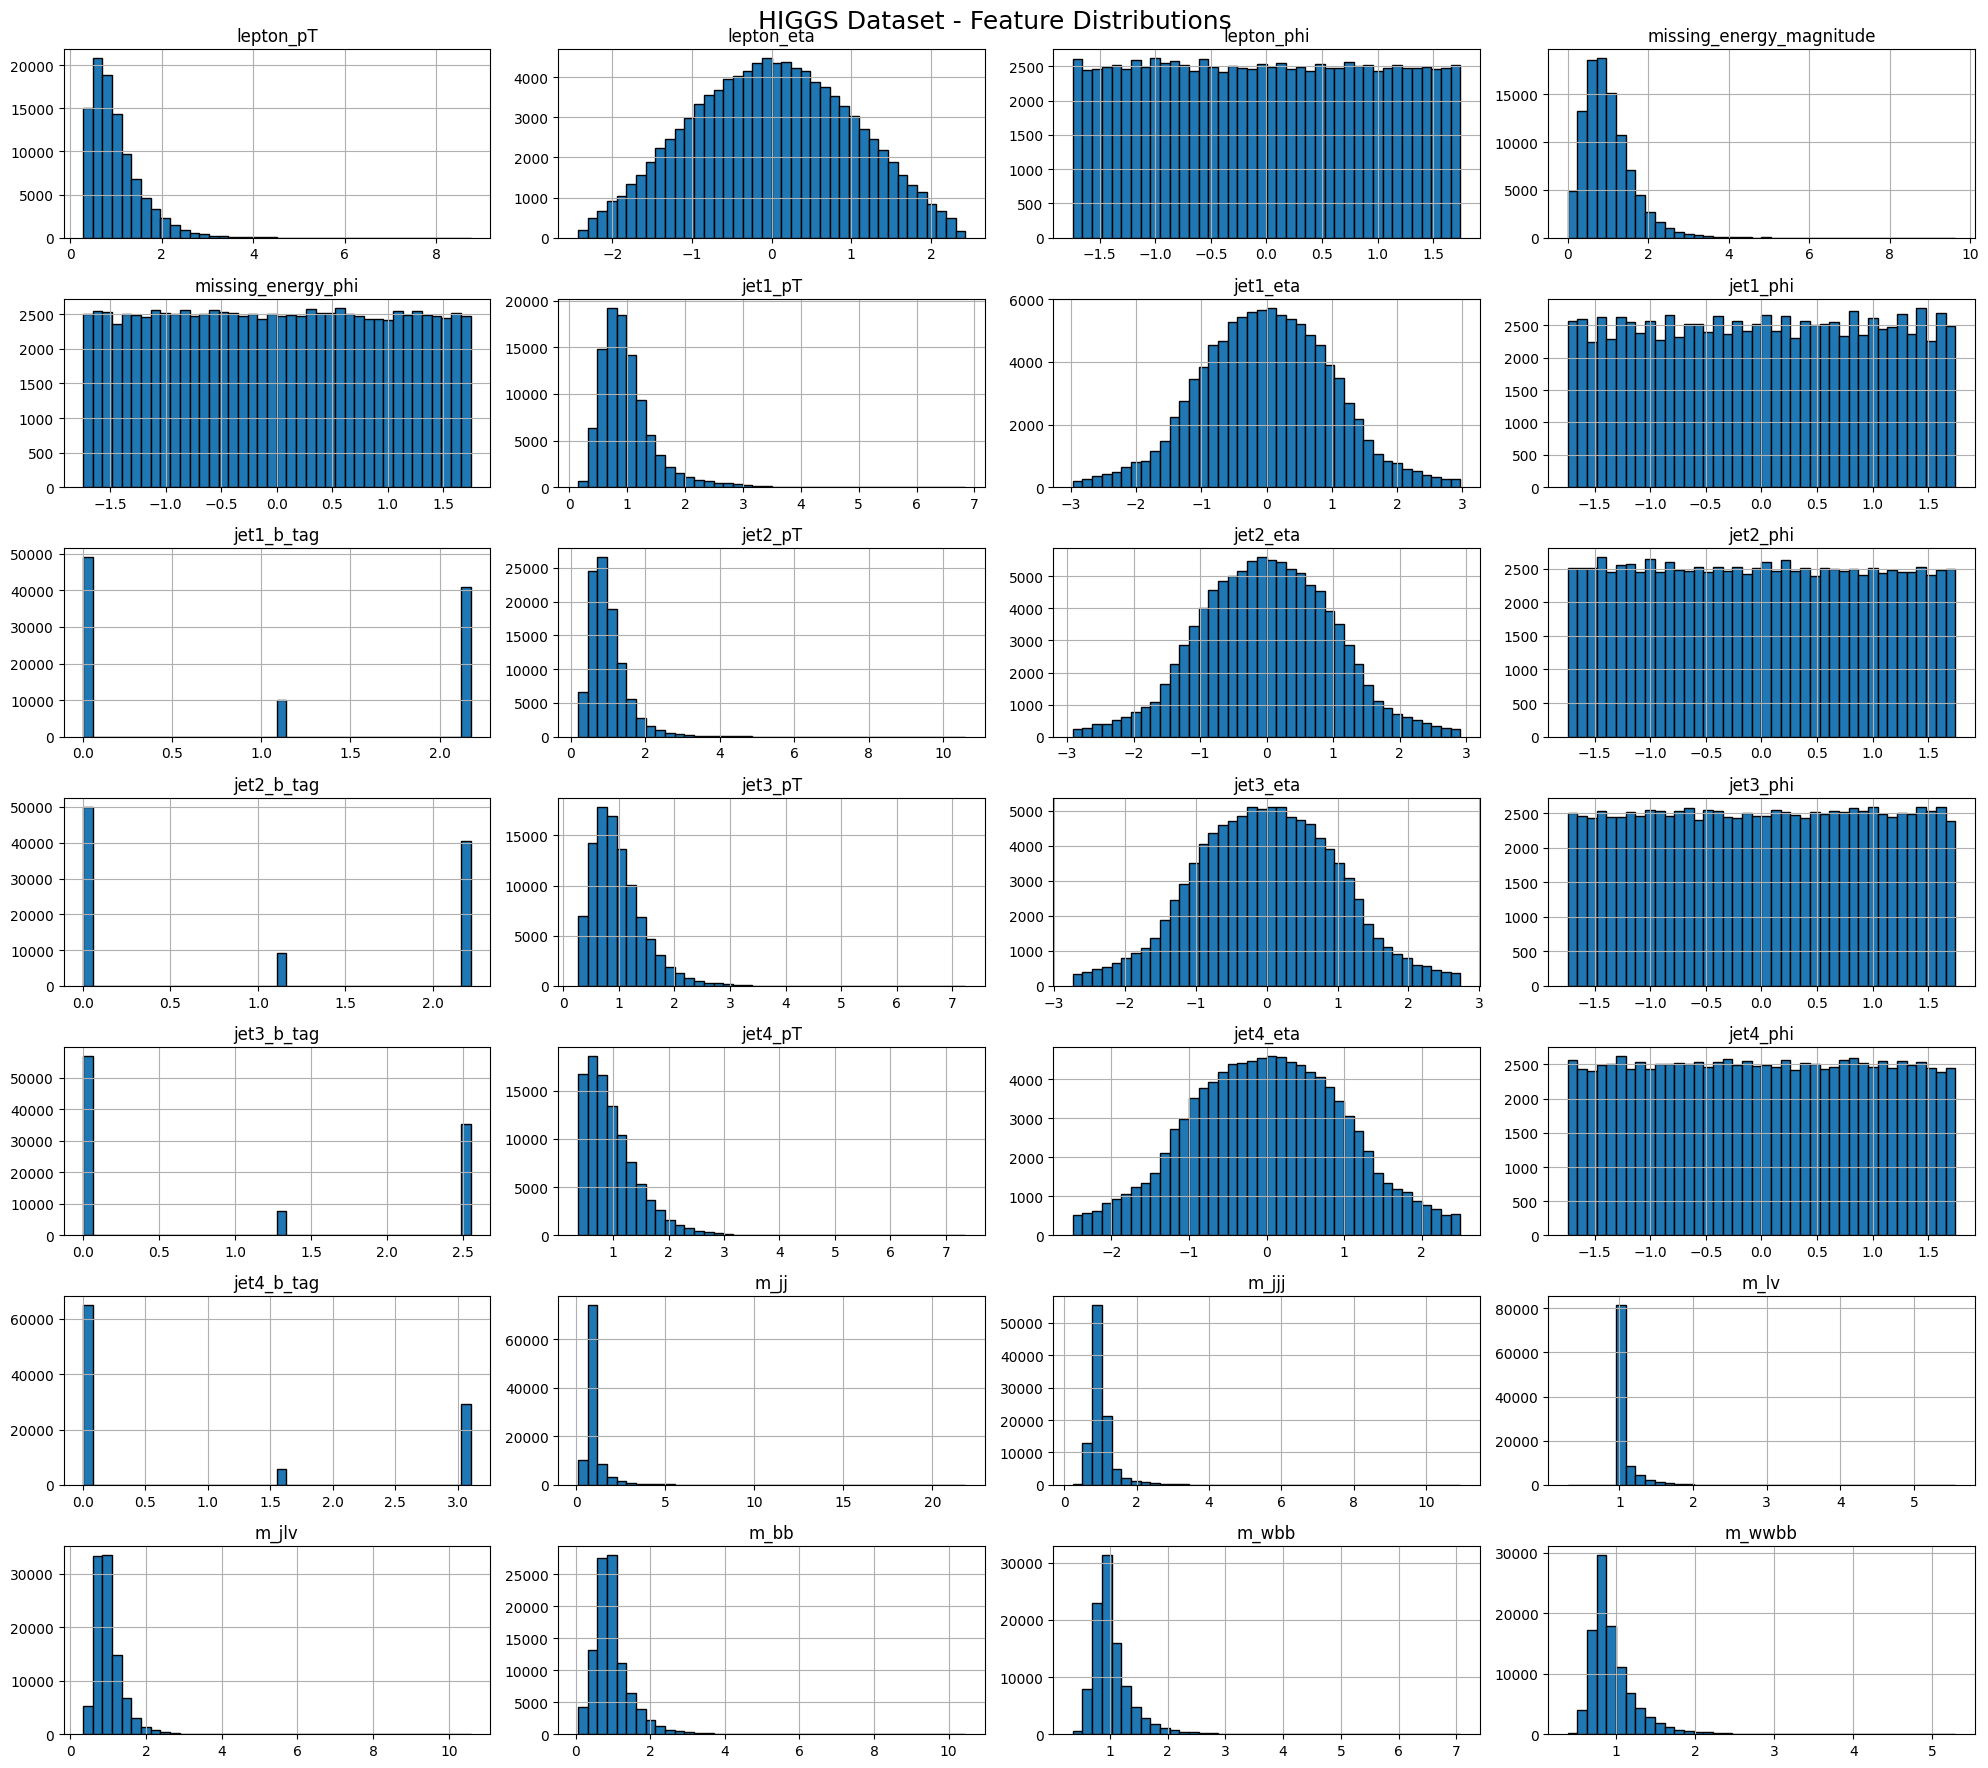

In [32]:

import matplotlib.pyplot as plt

# Sample only for visualization
plot_df = df.sample(
    n=100_000,
    random_state=42
)

features = plot_df.drop(columns=["target"])

features.hist(
    bins=40,
    figsize=(20, 18),
    layout=(7, 4),
    edgecolor="black"
)

plt.suptitle(
    "HIGGS Dataset - Feature Distributions",
    fontsize=18
)

plt.tight_layout()
plt.show()



### 8.2 Feature Skewness

Calculate skewness to identify asymmetric feature distributions.


In [33]:

skewness = df.drop(
    columns=["target"]
).skew()

print("Feature Skewness:")
display(skewness.sort_values(ascending=False))


Feature Skewness:


,0
m_jj,6.516702
m_jjj,4.999136
m_lv,4.621131
m_jlv,2.853527
m_wbb,2.686348
m_wwbb,2.547701
m_bb,2.425861
jet2_pT,1.968347
jet1_pT,1.904673
lepton_pT,1.758389



## 9. Outlier Analysis

### 9.1 Feature Boxplots

Visualize potential outliers in the numerical features using boxplots.


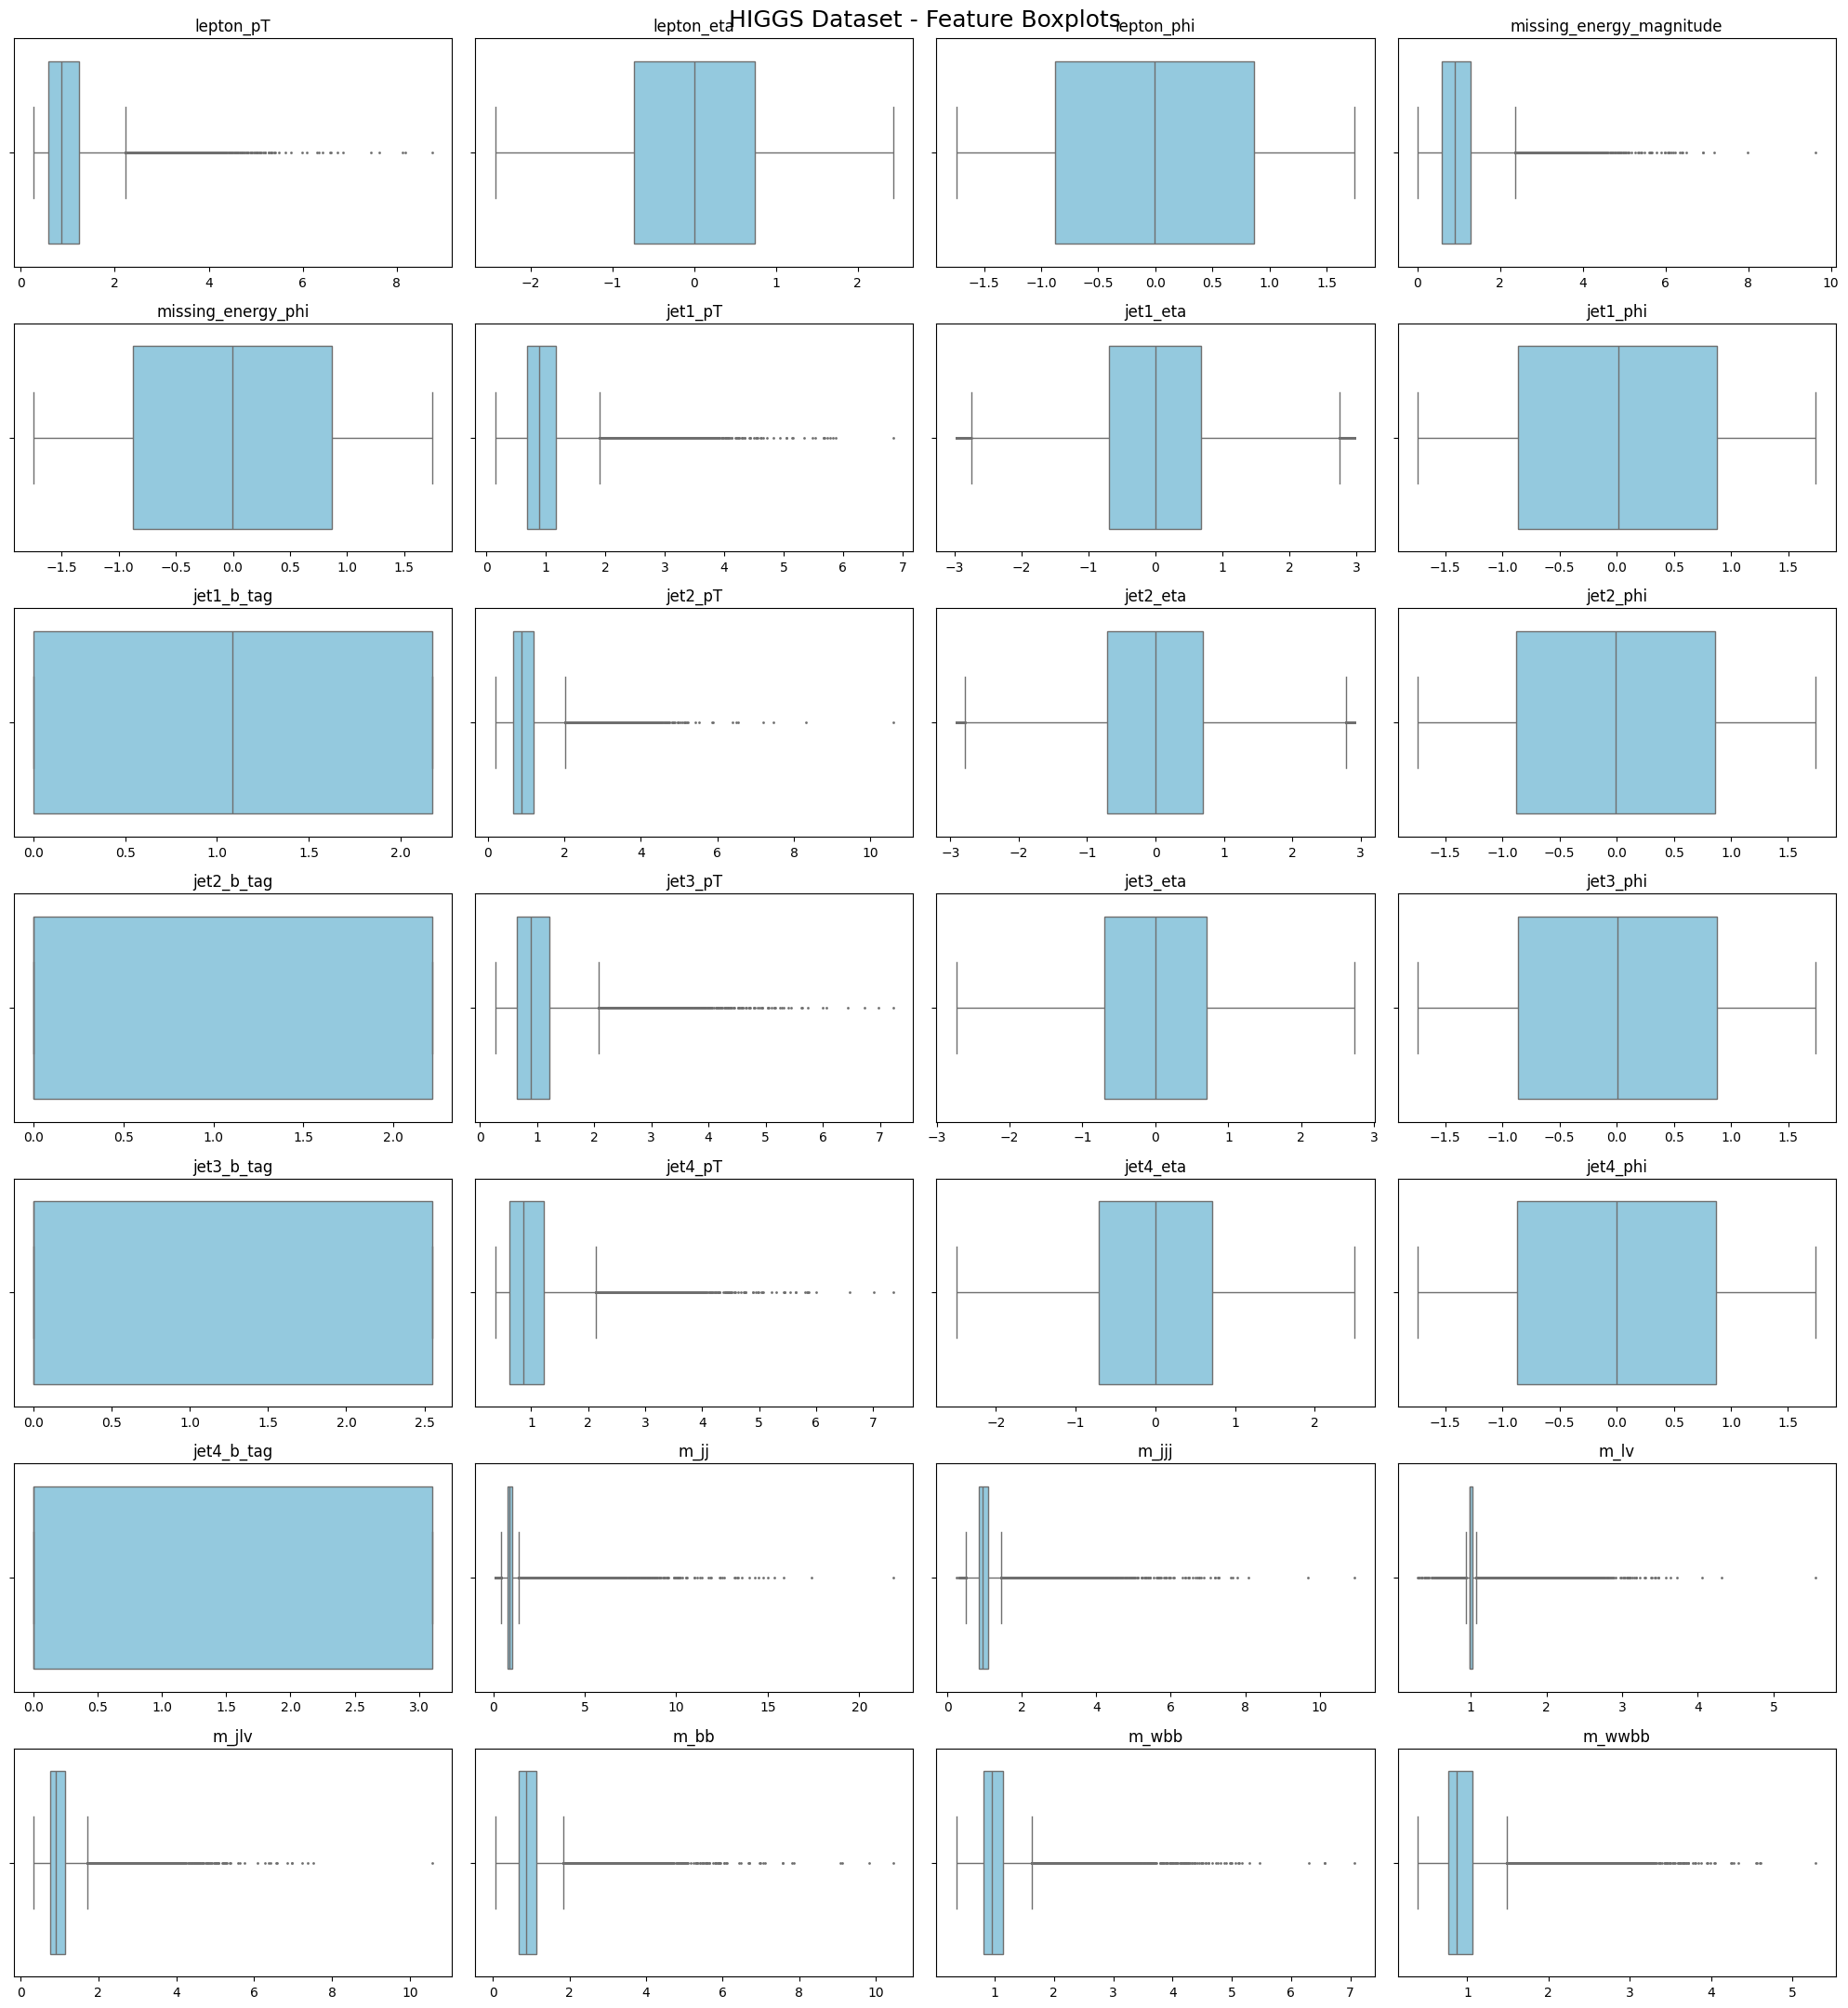

In [35]:

import matplotlib.pyplot as plt
import seaborn as sns

features = plot_df.drop(columns=["target"])

fig, axes = plt.subplots(
    7, 4,
    figsize=(20, 22)
)

axes = axes.flatten()

for i, column in enumerate(features.columns):
    sns.boxplot(
        x=features[column],
        ax=axes[i],
        color="skyblue",
        showfliers=True,
        fliersize=1
    )

    axes[i].set_title(column)
    axes[i].set_xlabel("")

plt.suptitle(
    "HIGGS Dataset - Feature Boxplots",
    fontsize=18
)

plt.tight_layout()
plt.show()



### 9.2 IQR-Based Outlier Detection

Identify potential outliers using the Interquartile Range (IQR) method.


In [36]:

feature_df = df.drop(columns=["target"])

Q1 = feature_df.quantile(0.25)
Q3 = feature_df.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = (
    (feature_df < lower_bound) |
    (feature_df > upper_bound)
).sum()

outlier_percentages = (
    outlier_counts / len(feature_df) * 100
)

outlier_summary = pd.DataFrame({
    "Outlier Count": outlier_counts,
    "Outlier Percentage (%)": outlier_percentages.round(2)
})

display(
    outlier_summary.sort_values(
        by="Outlier Percentage (%)",
        ascending=False
    )
)


,Outlier Count,Outlier Percentage (%)
m_lv,2185644,19.87
m_jj,1535805,13.96
m_jjj,823177,7.48
m_wbb,690031,6.27
m_bb,666944,6.06
m_wwbb,659860,6.00
m_jlv,562323,5.11
jet1_pT,544742,4.95
jet2_pT,441388,4.01
lepton_pT,429914,3.91



## 10. Correlation Analysis

### 10.1 Feature Correlation Heatmap

Analyze linear relationships between numerical features using Pearson correlation.


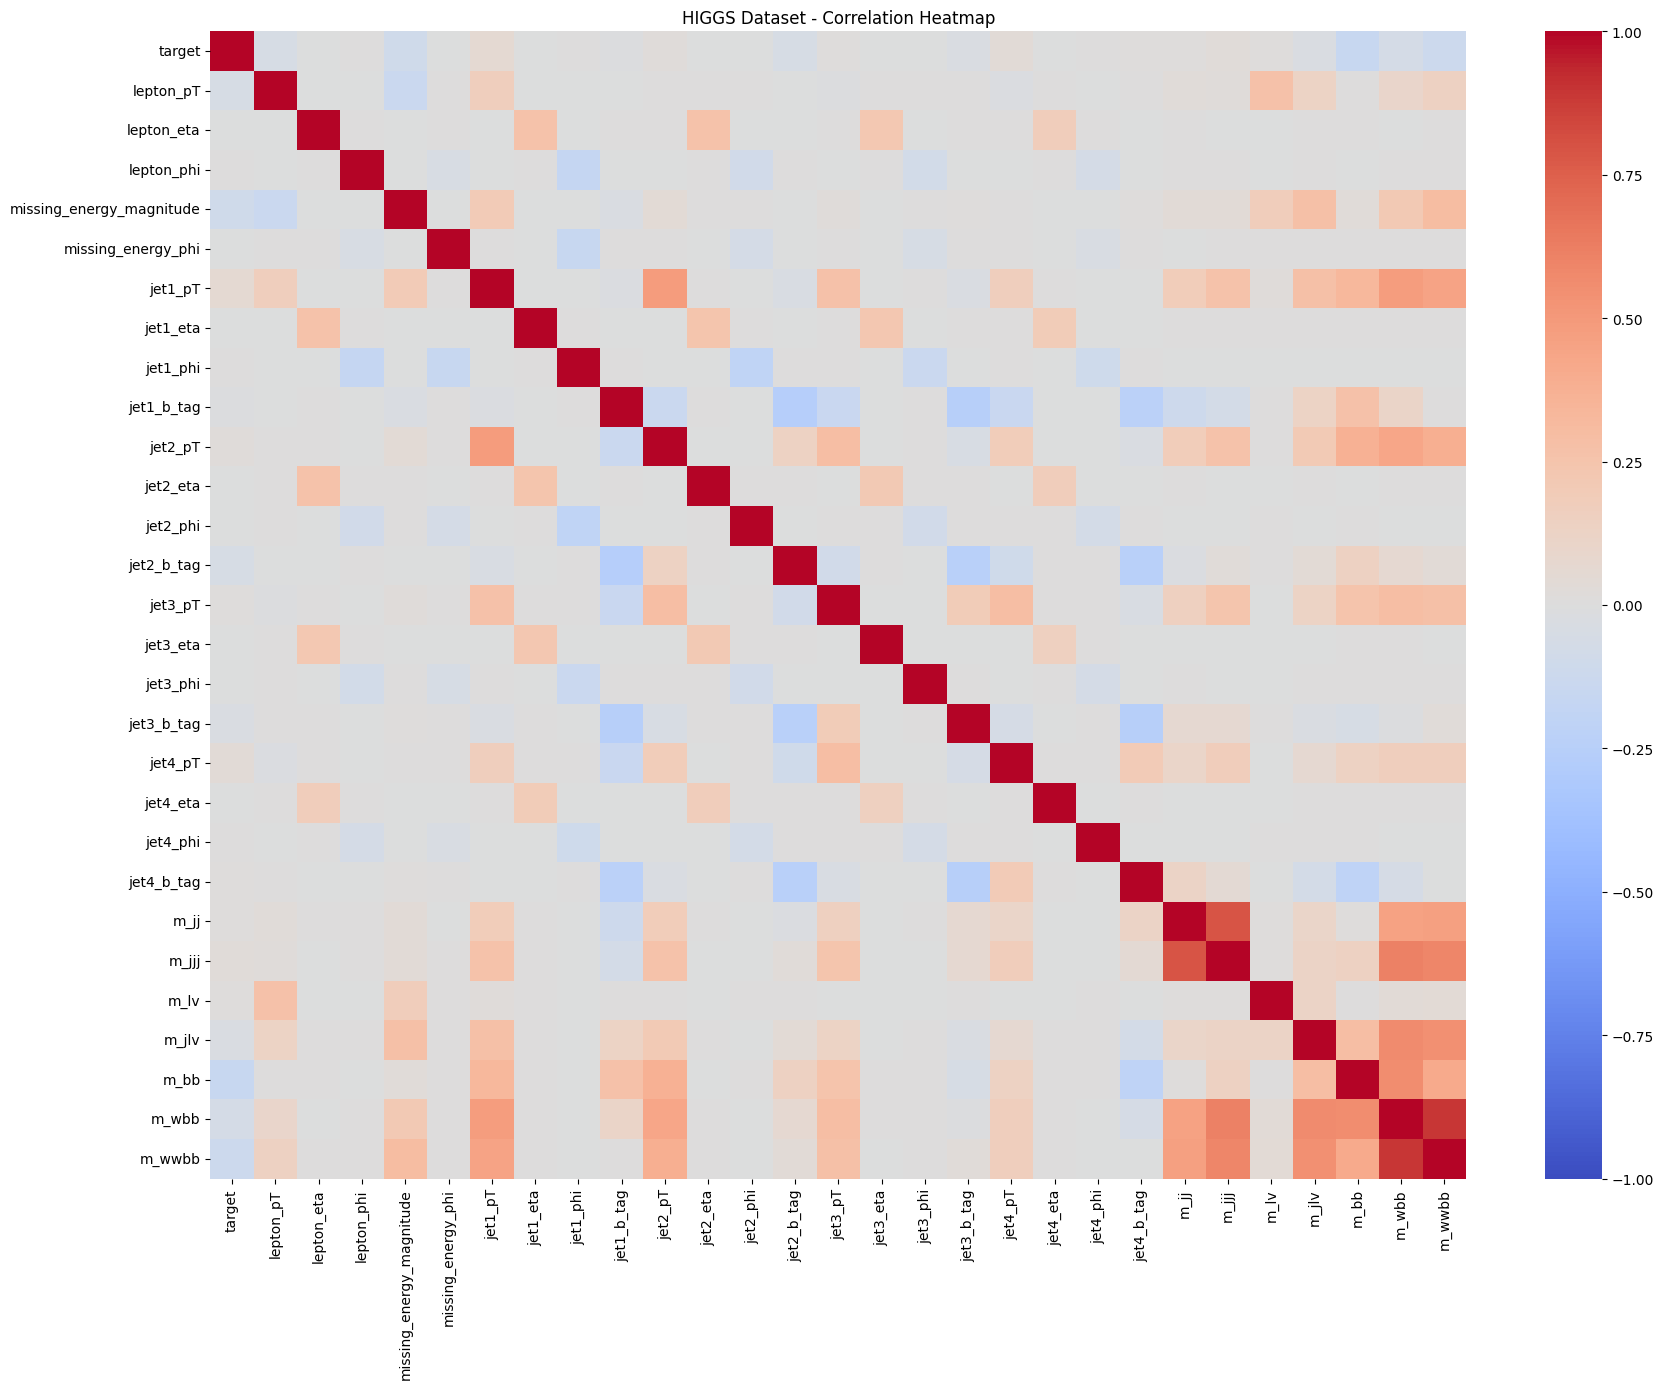

In [38]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlations using the full dataset
correlation_matrix = df.corr(method="pearson")

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False
)

plt.title("HIGGS Dataset - Correlation Heatmap")
plt.tight_layout()
plt.show()



### 10.2 Feature Correlation with Target

Identify features with stronger positive or negative linear relationships with the target variable.


,Pearson Correlation
jet1_pT,0.056908
jet4_pT,0.037140
m_jjj,0.025545
jet2_pT,0.021891
jet4_b_tag,0.015057
jet3_pT,0.014865
m_jj,0.012852
m_lv,0.010999
lepton_phi,0.000643
jet4_phi,0.000432


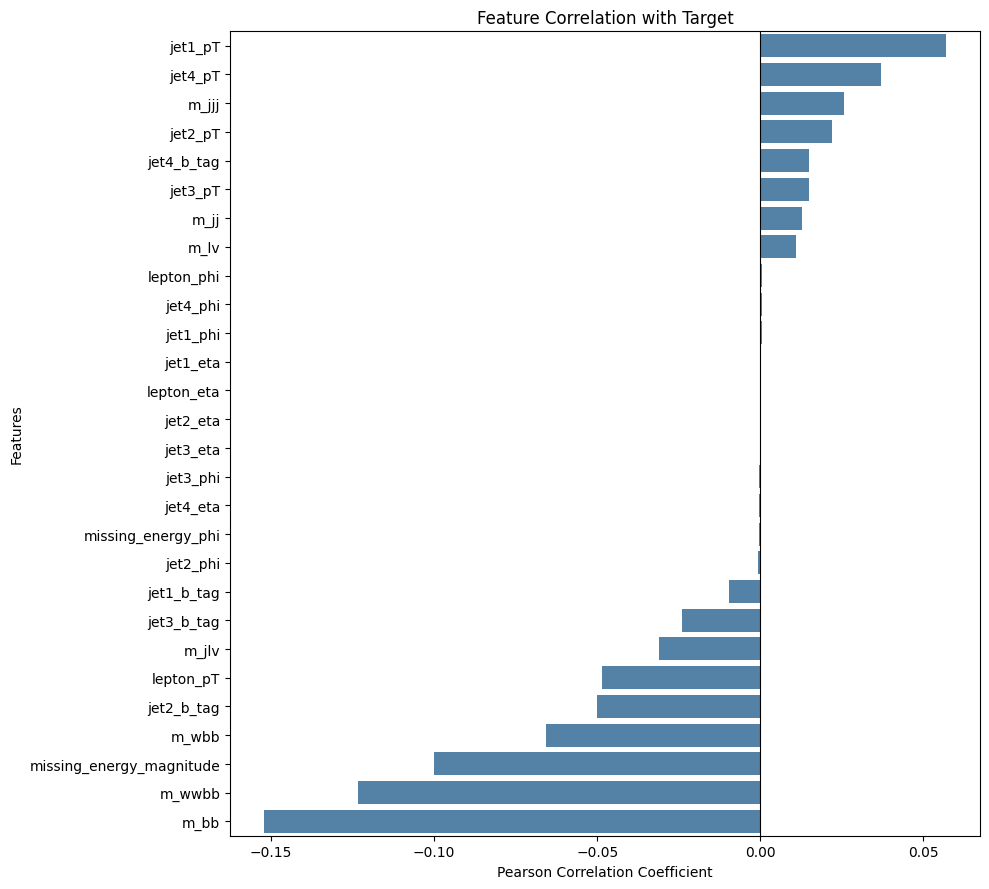

In [39]:

target_correlation = (
    correlation_matrix["target"]
    .drop("target")
    .sort_values(ascending=False)
)

display(target_correlation.to_frame("Pearson Correlation"))

plt.figure(figsize=(10, 9))

sns.barplot(
    x=target_correlation.values,
    y=target_correlation.index,
    color="steelblue"
)

plt.title("Feature Correlation with Target")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Features")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()



### 10.3 Highly Correlated Feature Pairs

Identify feature pairs with an absolute Pearson correlation greater than 0.8.


In [40]:

import numpy as np

feature_corr = correlation_matrix.drop(
    index="target",
    columns="target"
)

upper_triangle = feature_corr.where(
    np.triu(
        np.ones(feature_corr.shape, dtype=bool),
        k=1
    )
)

high_corr_pairs = (
    upper_triangle.stack()
    .loc[lambda x: x.abs() > 0.8]
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

print("Number of highly correlated feature pairs:", len(high_corr_pairs))
display(high_corr_pairs)


Number of highly correlated feature pairs: 1


,,0
m_wbb,m_wwbb,0.895267



### 10.4 Correlation Analysis Summary

Pearson correlation analysis was performed on the complete dataset to examine linear relationships among features and with the target variable.

Highly correlated feature pairs were identified using a threshold of 0.8.

**Conclusion:** Correlation results will guide further analysis. Features will not be removed solely based on correlation.



## 11. Exploratory Data Analysis Summary

EDA was performed on the complete HIGGS dataset containing 11 million records and 28 input features.

### Key Findings

- **Total Records:** 11,000,000
- **Input Features:** 28
- **Target Classes:** Higgs Signal Event (1), Background Event (0)
- **Missing Values:** 0
- **Infinite Values:** 0
- **Invalid Target Values:** 0
- **Exact Duplicate Records:** 278,698 (2.5336%)
- **Conflicting Target Groups:** 0

### Conclusion

The dataset passed the initial data quality checks. Feature distributions, outliers, and correlations were analyzed.

Potential outliers will be retained unless further analysis justifies their removal. Duplicate handling and data leakage prevention will be considered during preprocessing.

The dataset is ready for preprocessing and machine learning model development.
